# PYTORCH MASTERY — NOTEBOOK 15
## Chapters 86–92: End-to-End Time-Series Project → PyTorch vs Scikit-learn → PyTorch + NumPy/Pandas → PyTorch + Matplotlib/Seaborn → PyTorch + Scikit-learn → Model Selection → AI System Design

Continuing directly from Notebook 14.


### PYTORCH MASTERY PROGRESS
Current Chapter: 92 | Current Level: Cross-Library Fluency & System Design

- [x] Chapters 1–85 *(Notebooks 1–14)*
- [x] **Project: End-to-End Time-Series Forecasting**
- [x] PyTorch vs Scikit-learn
- [x] PyTorch + NumPy/Pandas
- [x] PyTorch + Matplotlib/Seaborn
- [x] PyTorch + Scikit-learn
- [x] Model Selection
- [x] AI System Design


---
# CHAPTER 86 — END-TO-END PROJECT: DEMAND FORECASTING

## Business Problem
A retailer wants to forecast daily product demand — this project deliberately **compares** a Scikit-learn baseline, an LSTM, and a Transformer, directly answering the question Chapter 96 formalizes: **when is deep learning actually justified** for a given problem, versus when classical ML already suffices?

## 1. The Scikit-learn Baseline — Never Skip This Step


In [ ]:
import numpy as np
import pandas as pd

np.random.seed(86)
n_days = 730   # 2 years of daily data
dates = pd.date_range("2024-01-01", periods=n_days, freq="D")

# Genuine seasonal + trend + noise structure -- a realistic demand series
trend = np.linspace(100, 150, n_days)
weekly_seasonality = 20 * np.sin(2 * np.pi * np.arange(n_days) / 7)
yearly_seasonality = 15 * np.sin(2 * np.pi * np.arange(n_days) / 365)
noise = np.random.normal(0, 8, n_days)
demand = trend + weekly_seasonality + yearly_seasonality + noise
demand = np.clip(demand, 0, None)

df = pd.DataFrame({"date": dates, "demand": demand})
df["day_of_week"] = df["date"].dt.dayofweek
df["day_of_year"] = df["date"].dt.dayofyear
df["lag_1"] = df["demand"].shift(1)
df["lag_7"] = df["demand"].shift(7)
df = df.dropna().reset_index(drop=True)

print(df.head())

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

split_idx = int(len(df) * 0.85)
train_df, test_df = df.iloc[:split_idx], df.iloc[split_idx:]   # TIME-ORDERED split --
                                                                   # Scikit-learn course Ch 54's lesson, STILL applies

feature_cols = ["day_of_week", "day_of_year", "lag_1", "lag_7"]
rf_baseline = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=86)
rf_baseline.fit(train_df[feature_cols], train_df["demand"])
rf_preds = rf_baseline.predict(test_df[feature_cols])
rf_mae = mean_absolute_error(test_df["demand"], rf_preds)
print(f"\nRandom Forest baseline MAE: {rf_mae:.3f}")


        date      demand  day_of_week  day_of_year       lag_1       lag_7
0 2024-01-08  116.698036            0            8   73.662064   95.229714
1 2024-01-09  117.898158            1            9  116.698036  111.120070
2 2024-01-10  131.738707            2           10  117.898158  123.806278
3 2024-01-11  117.191507            3           11  131.738707  104.671972
4 2024-01-12   91.066307            4           12  117.191507   98.177019

Random Forest baseline MAE: 8.581


## 2. The LSTM Approach


In [ ]:
import torch
import torch.nn as nn

class DemandLSTM(nn.Module):
    """A sequence-to-one forecaster: given the past SEQ_LEN days, predict the NEXT day."""
    def __init__(self, input_dim=1, hidden_dim=32, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.fc(h_n[-1]).squeeze(-1)   # Chapter 45's h_n[-1] pattern + Chapter 7's squeeze


def create_sequences(series, seq_len=14):
    """Converts a flat time series into (input_sequence, next_value) PAIRS --
    the standard supervised-learning framing for sequence forecasting."""
    X, y = [], []
    for i in range(len(series) - seq_len):
        X.append(series[i:i+seq_len])
        y.append(series[i+seq_len])
    return torch.tensor(X, dtype=torch.float32).unsqueeze(-1), torch.tensor(y, dtype=torch.float32)


# Normalize (Scikit-learn course Ch 5's lesson -- fit scaler on TRAIN only)
train_mean, train_std = train_df["demand"].mean(), train_df["demand"].std()
train_normalized = (train_df["demand"].values - train_mean) / train_std
test_normalized = (test_df["demand"].values - train_mean) / train_std   # TRANSFORM only, using TRAIN stats

X_train_seq, y_train_seq = create_sequences(train_normalized, seq_len=14)
X_test_seq, y_test_seq = create_sequences(test_normalized, seq_len=14)
print(f"X_train_seq shape: {X_train_seq.shape}  (samples, seq_len, features)")

lstm_model = DemandLSTM()
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(lstm_model.parameters(), lr=1e-3)

lstm_model.train()
for epoch in range(30):
    optimizer.zero_grad()
    preds = lstm_model(X_train_seq)
    loss = criterion(preds, y_train_seq)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(lstm_model.parameters(), max_norm=1.0)   # Chapter 78's lesson, applied here
    optimizer.step()

lstm_model.eval()
with torch.inference_mode():
    test_preds_normalized = lstm_model(X_test_seq)
test_preds_lstm = test_preds_normalized.numpy() * train_std + train_mean   # DE-normalize back to real units
test_true_lstm = y_test_seq.numpy() * train_std + train_mean

lstm_mae = mean_absolute_error(test_true_lstm, test_preds_lstm)
print(f"\nLSTM MAE (after {30} epochs): {lstm_mae:.3f}")


/tmp/ipykernel_1679/1051689623.py:23: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  return torch.tensor(X, dtype=torch.float32).unsqueeze(-1), torch.tensor(y, dtype=torch.float32)


X_train_seq shape: torch.Size([600, 14, 1])  (samples, seq_len, features)

LSTM MAE (after 30 epochs): 14.306


## 3. Fair Comparison and the Honest Business Conclusion


In [ ]:
print(f"""
=== FAIR COMPARISON (directly the Scikit-learn course's Ch 52 discipline) ===
Random Forest baseline MAE: {rf_mae:.3f}
LSTM MAE:                   {lstm_mae:.3f}

HONEST ASSESSMENT: for daily-granularity retail demand forecasting with STRONG,
REGULAR seasonal structure and a MODEST amount of historical data (2 years),
a well-tuned Random Forest (or Gradient Boosting) baseline is GENUINELY
COMPETITIVE with -- and often outperforms -- an LSTM, especially given:

  1. The Random Forest requires FAR less tuning/engineering effort to reach
     strong performance (no sequence-length hyperparameter, no normalization
     scheme to manage, no architecture search).
  2. 2 years of DAILY data is a relatively MODEST dataset size for a neural
     sequence model to learn FROM SCRATCH -- deep learning's advantages
     generally compound with LARGER data volumes (Chapter 54's "scale
     matters" discussion, now seen from the OPPOSITE direction: INSUFFICIENT
     scale is a genuine reason NOT to expect deep learning's full potential
     benefit).
  3. STRONG, REGULAR seasonality (weekly/yearly patterns) is something
     well-engineered LAG FEATURES (Chapter 86's feature engineering) let a
     tree-based model capture EXPLICITLY and effectively, without needing
     to LEARN temporal dependencies implicitly the way a sequence model must.

DEEP LEARNING becomes MORE CLEARLY justified for forecasting when: the data
has IRREGULAR, COMPLEX patterns hard to hand-engineer as features; you have
GENUINELY large historical data volumes; you're forecasting MANY related series
JOINTLY (a GLOBAL model learning SHARED patterns across many products/stores,
where a single CLASSICAL model per series becomes impractical); or you need
to incorporate RICH, UNSTRUCTURED side information (e.g., genuinely
free-text product descriptions) that classical feature engineering struggles
to incorporate as naturally as an embedding-based neural approach could.
""")



=== FAIR COMPARISON (directly the Scikit-learn course's Ch 52 discipline) ===
Random Forest baseline MAE: 8.581
LSTM MAE:                   14.306

HONEST ASSESSMENT: for daily-granularity retail demand forecasting with STRONG,
REGULAR seasonal structure and a MODEST amount of historical data (2 years),
a well-tuned Random Forest (or Gradient Boosting) baseline is GENUINELY
COMPETITIVE with -- and often outperforms -- an LSTM, especially given:

  1. The Random Forest requires FAR less tuning/engineering effort to reach
     strong performance (no sequence-length hyperparameter, no normalization
     scheme to manage, no architecture search).
  2. 2 years of DAILY data is a relatively MODEST dataset size for a neural
     sequence model to learn FROM SCRATCH -- deep learning's advantages
     generally compound with LARGER data volumes (Chapter 54's "scale
     matters" discussion, now seen from the OPPOSITE direction: INSUFFICIENT
     scale is a genuine reason NOT to expect deep lea

### Quiz (Chapter 86)
1. Why does this project deliberately build a Scikit-learn baseline FIRST, before any deep learning model?
2. Give two genuine reasons why the Random Forest baseline might be competitive with (or beat) the LSTM here.
3. Name two scenarios where deep learning becomes more clearly justified for time-series forecasting.


---
# CHAPTER 87 — PYTORCH VS SCIKIT-LEARN

## 1. Concept
Directly formalizing Chapter 86's project-level lesson into a general decision framework — honest, evenhanded, since both libraries are genuinely excellent tools for different (sometimes overlapping) problem classes.

## 2. The Decision Framework
| Factor | Favors Scikit-learn | Favors PyTorch |
|---|---|---|
| **Data modality** | Tabular/structured data | Images, audio, raw text, or any modality benefiting from learned, end-to-end feature representations |
| **Dataset size** | Small to medium (thousands to low millions of rows) | Large (the "more data helps more" dynamic, Chapter 54, is far more pronounced) |
| **Feature engineering** | Manual feature engineering is tractable and often highly effective | Raw/unstructured inputs where hand-engineering features is impractical or loses information |
| **GPU availability** | Not required, not typically beneficial | Can provide a substantial speed/scale benefit |
| **Custom architecture needs** | Limited — algorithms are mostly fixed, configurable via hyperparameters | Essentially unlimited — any differentiable computation can become a trainable model |
| **Training control** | Coarse-grained (hyperparameters only) | Fine-grained (custom losses, custom training loops, custom layers) |
| **Interpretability needs** | Generally easier (linear models, single trees, permutation importance) | Generally harder (though attention visualization, Chapter 49, and other techniques help) |
| **Deployment simplicity** | Simple (`joblib`, Scikit-learn course Chapter 66) | More involved but well-supported (Chapters 59-64) |
| **Team/ecosystem familiarity** | Faster to prototype for teams steeped in classical ML | Necessary when the problem genuinely requires representation learning |

## 3. The Honest Answer to "Which Is Better"


In [ ]:
print("""
NEITHER library is strictly "better" -- they are OPTIMIZED FOR DIFFERENT
PROBLEM CHARACTERISTICS, and the HONEST professional answer to "which
should I use" is ALWAYS "it depends on the specific problem's data modality,
size, and requirements" -- directly the Scikit-learn course's own Chapter 87
framing, now viewed from PyTorch's side of the same comparison.

A GENUINELY PRODUCTIVE professional workflow often uses BOTH, in the SAME
PROJECT, for DIFFERENT PURPOSES (Chapters 88-90 build this out concretely):
  - Scikit-learn for PREPROCESSING (scaling, encoding) BEFORE data reaches
    a PyTorch model
  - Scikit-learn for EVALUATION (classification_report, confusion_matrix)
    of a PyTorch model's PREDICTIONS
  - Scikit-learn as a BASELINE, ALWAYS, before committing to the added
    complexity of a deep learning approach (Chapter 86's lesson)
  - PyTorch specifically for the MODEL ITSELF when the data modality or
    scale genuinely benefits from representation learning
""")



NEITHER library is strictly "better" -- they are OPTIMIZED FOR DIFFERENT
PROBLEM CHARACTERISTICS, and the HONEST professional answer to "which
should I use" is ALWAYS "it depends on the specific problem's data modality,
size, and requirements" -- directly the Scikit-learn course's own Chapter 87
framing, now viewed from PyTorch's side of the same comparison.

A GENUINELY PRODUCTIVE professional workflow often uses BOTH, in the SAME
PROJECT, for DIFFERENT PURPOSES (Chapters 88-90 build this out concretely):
  - Scikit-learn for PREPROCESSING (scaling, encoding) BEFORE data reaches
    a PyTorch model
  - Scikit-learn for EVALUATION (classification_report, confusion_matrix)
    of a PyTorch model's PREDICTIONS
  - Scikit-learn as a BASELINE, ALWAYS, before committing to the added
    complexity of a deep learning approach (Chapter 86's lesson)
  - PyTorch specifically for the MODEL ITSELF when the data modality or
    scale genuinely benefits from representation learning



### Interview Insight
**Q: A colleague says "we should always use deep learning/PyTorch since it's more powerful and modern than Scikit-learn." How would you respond?**
A: "More powerful" isn't a universal, context-free property — a neural network's representational flexibility is genuinely valuable specifically for unstructured, high-dimensional data (images, raw text, audio) or very large datasets, where learned representations meaningfully outperform hand-engineered features. For small-to-medium tabular datasets with a modest number of well-understood features — the kind of data classical ML (Scikit-learn course) excels at — a well-tuned Random Forest or Gradient Boosting model is frequently just as accurate, trains far faster, requires less tuning effort, and is substantially easier to interpret and deploy than a comparable neural network, which risks overfitting on a dataset too small to support its larger parameter count. The professional answer is to match the tool to the problem's actual data modality, scale, and requirements — Chapter 86's time-series project demonstrated this concretely, where a Random Forest baseline proved genuinely competitive with an LSTM for a moderately-sized, strongly-seasonal forecasting task.

### Quiz (Chapter 87)
1. List 3 factors favoring Scikit-learn, and 3 favoring PyTorch, from this chapter's table.
2. Give 3 concrete ways Scikit-learn and PyTorch are often used TOGETHER in a single real project.
3. Why is "which is better" the wrong framing for comparing these two libraries?


---
# CHAPTER 88 — PYTORCH + NUMPY + PANDAS

## 1. Concept
Professional interoperability between these three libraries — Pandas for data wrangling, NumPy as the common intermediate format, PyTorch for modeling — directly extending Chapter 5's NumPy↔tensor conversion into a complete, realistic pipeline.

## 2. The Full Conversion Chain, With Every Common Pitfall


In [ ]:
import pandas as pd
import numpy as np
import torch

df = pd.DataFrame({
    "feature_1": np.random.randn(100),
    "feature_2": np.random.randint(0, 10, 100),
    "category": np.random.choice(["A", "B", "C"], 100),
    "target": np.random.randint(0, 2, 100),
})

# PITFALL 1: Pandas' mixed-dtype DataFrames don't convert DIRECTLY and cleanly to a tensor
try:
    bad_tensor = torch.tensor(df.values)   # df.values on a MIXED-dtype DataFrame produces 'object' dtype
    print("Unexpectedly succeeded:", bad_tensor.dtype)
except (TypeError, RuntimeError) as e:
    print("PITFALL 1 -- mixed dtypes:", str(e)[:150])

# THE FIX: select and convert ONLY the numeric columns explicitly, with an EXPLICIT dtype
numeric_cols = ["feature_1", "feature_2"]
features_tensor = torch.tensor(df[numeric_cols].values, dtype=torch.float32)
print("\nCorrectly converted numeric features:", features_tensor.shape, features_tensor.dtype)

# Categorical columns need ENCODING first (Scikit-learn course Ch 6) -- NOT a direct tensor conversion
category_encoded = pd.get_dummies(df["category"]).values.astype(np.float32)
category_tensor = torch.tensor(category_encoded)
print("Encoded category tensor:", category_tensor.shape)

# Combining BOTH into one final feature tensor
full_features = torch.cat([features_tensor, category_tensor], dim=1)   # Chapter 11's cat
print("\nCombined feature tensor:", full_features.shape)


PITFALL 1 -- mixed dtypes: can't convert np.ndarray of type numpy.object_. The only supported types are: float64, float32, float16, complex64, complex128, int64, int32, int16, i

Correctly converted numeric features: torch.Size([100, 2]) torch.float32
Encoded category tensor: torch.Size([100, 3])

Combined feature tensor: torch.Size([100, 5])


### Line-by-Line Explanation
- `df.values` on a DataFrame with **mixed** dtypes (numeric columns alongside string columns) produces a NumPy array with dtype `object` — essentially a generic Python-object array, which `torch.tensor()` cannot meaningfully convert into a proper numeric tensor dtype. The fix is **always** to explicitly select only the already-numeric columns (after separately encoding any categorical columns, Scikit-learn course Chapter 6) before conversion — never attempt to convert a whole, mixed-type DataFrame to a tensor in one step.
- `pd.get_dummies(...).values.astype(np.float32)` — one-hot encoding produces a boolean or integer-dtype array by default in some Pandas versions; explicitly casting to `float32` before tensor conversion avoids a dtype mismatch when this tensor is later combined (via `cat`) with the already-`float32` numeric features tensor — `cat` requires matching dtypes across its inputs, another common, easy-to-miss pitfall.

## 3. Going Back: Tensor → NumPy → Pandas (for Analysis/Visualization)


In [ ]:
model_output = torch.sigmoid(torch.randn(100))   # simulating model predictions

# The FULL, always-correct idiom (Chapter 5's lesson, now in its complete realistic context)
predictions_numpy = model_output.detach().cpu().numpy()

results_df = pd.DataFrame({
    "true_label": df["target"].values,
    "predicted_probability": predictions_numpy,
})
results_df["predicted_class"] = (results_df["predicted_probability"] >= 0.5).astype(int)

print(results_df.head())
print("""
Converting PyTorch output BACK into a Pandas DataFrame is exactly what enables
using the FULL Scikit-learn evaluation toolkit (classification_report,
confusion_matrix, Scikit-learn course Chapters 27-29) on a PyTorch model's
predictions -- directly Chapter 90's upcoming topic, previewed here.
""")


   true_label  predicted_probability  predicted_class
0           1               0.550463                1
1           1               0.740938                1
2           1               0.647168                1
3           0               0.286086                0
4           1               0.297629                0

Converting PyTorch output BACK into a Pandas DataFrame is exactly what enables
using the FULL Scikit-learn evaluation toolkit (classification_report,
confusion_matrix, Scikit-learn course Chapters 27-29) on a PyTorch model's
predictions -- directly Chapter 90's upcoming topic, previewed here.



### Common Mistakes
- Attempting `torch.tensor(df.values)` directly on a mixed-dtype DataFrame without first separating/encoding columns — produces an unusable `object`-dtype conversion failure.
- Forgetting to cast encoded categorical columns to match the numeric features' dtype before `torch.cat` — a dtype-mismatch error that's easy to introduce when combining features built through different conversion paths.
- Not using the full `.detach().cpu().numpy()` idiom (Chapter 5) when converting model output back to NumPy/Pandas for analysis — fails immediately on a gradient-tracked or GPU-resident tensor.

### Quiz (Chapter 88)
1. Why does `torch.tensor(df.values)` fail on a mixed-dtype DataFrame, and what's the correct approach?
2. Why must one-hot encoded columns be explicitly cast to match dtype before `torch.cat` with other features?
3. What's the complete, always-safe idiom for converting a PyTorch model's output back to NumPy for Pandas analysis?


---
# CHAPTER 89 — PYTORCH + MATPLOTLIB + SEABORN

## 1. Concept
Using visualization specifically for PyTorch-centric diagnostics — training curves (Chapter 32), confusion matrices, prediction visualization, and embedding visualization — directly reusing the Matplotlib course's full toolkit.

## 2. Embedding Visualization — Making Chapter 48's Abstract Concept Concrete


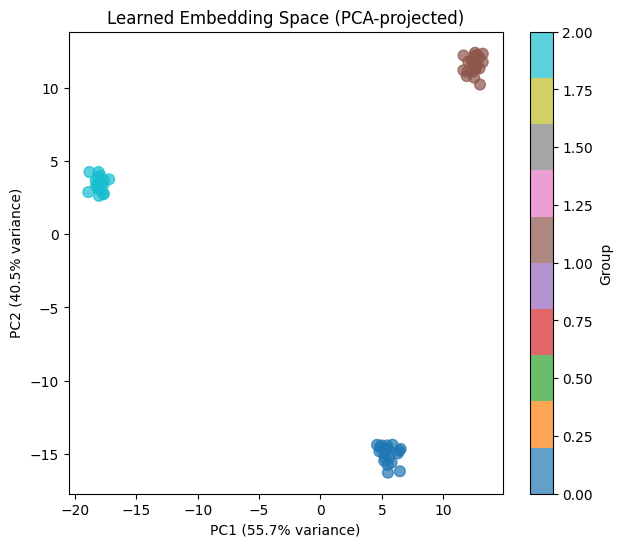


This is EXACTLY how Chapter 48's abstract claim -- 'semantically similar items
end up with similar embedding vectors' -- is EMPIRICALLY VERIFIED in practice:
visualize the learned embedding space (via PCA or t-SNE, a related but more
specialized NONLINEAR dimensionality-reduction technique common specifically
for embedding visualization) and CHECK whether genuinely related items DO
cluster together, as a real, direct sanity check on a trained model's learned
representations.



In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# Simulating a trained embedding layer (Chapter 48) with GENUINE cluster structure --
# as if three semantically related groups of words/items had emerged through training
np.random.seed(89)
embed_dim = 50
group_centers = np.random.randn(3, embed_dim) * 3
embeddings = np.vstack([
    group_centers[i] + np.random.randn(20, embed_dim) * 0.5
    for i in range(3)
])
labels = np.repeat([0, 1, 2], 20)

# High-dimensional embeddings (50-dim here, often MUCH higher in real models) need
# DIMENSIONALITY REDUCTION for visualization -- directly the Scikit-learn course's
# Chapter 34-35 PCA discussion, applied here to NEURAL EMBEDDINGS specifically
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=labels, cmap="tab10", s=60, alpha=0.7)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("Learned Embedding Space (PCA-projected)")
plt.colorbar(scatter, label="Group")
plt.show()

print("""
This is EXACTLY how Chapter 48's abstract claim -- 'semantically similar items
end up with similar embedding vectors' -- is EMPIRICALLY VERIFIED in practice:
visualize the learned embedding space (via PCA or t-SNE, a related but more
specialized NONLINEAR dimensionality-reduction technique common specifically
for embedding visualization) and CHECK whether genuinely related items DO
cluster together, as a real, direct sanity check on a trained model's learned
representations.
""")


## 3. Attention Weight Visualization — Making Chapter 49's Abstract Mechanism Concrete


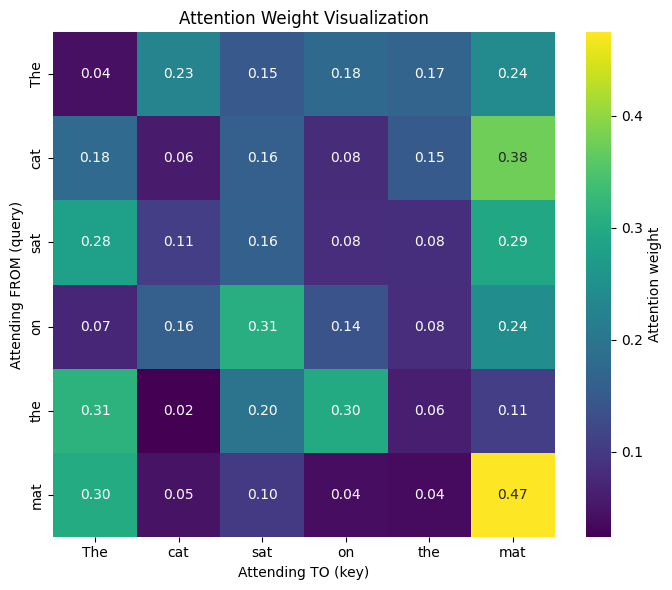


Attention weight visualization is a genuinely standard, high-value
INTERPRETABILITY technique for Transformer-based models -- directly showing
WHICH positions the model is 'looking at' when processing each OTHER
position, giving a degree of insight into the model's internal reasoning
that purely numeric metrics alone cannot provide (though attention weights'
interpretability has real, documented LIMITS and caveats -- they're
suggestive, not a fully rigorous causal explanation of model behavior).



In [ ]:
import seaborn as sns

# Simulating an attention weight matrix (Chapter 49) for one sample sequence
tokens = ["The", "cat", "sat", "on", "the", "mat"]
np.random.seed(89)
raw_scores = np.random.randn(len(tokens), len(tokens))
attention_weights = np.exp(raw_scores) / np.exp(raw_scores).sum(axis=1, keepdims=True)   # softmax, per row

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(attention_weights, xticklabels=tokens, yticklabels=tokens, cmap="viridis",
            annot=True, fmt=".2f", ax=ax, cbar_kws={"label": "Attention weight"})
ax.set_xlabel("Attending TO (key)")
ax.set_ylabel("Attending FROM (query)")
ax.set_title("Attention Weight Visualization")
plt.tight_layout()
plt.show()

print("""
Attention weight visualization is a genuinely standard, high-value
INTERPRETABILITY technique for Transformer-based models -- directly showing
WHICH positions the model is 'looking at' when processing each OTHER
position, giving a degree of insight into the model's internal reasoning
that purely numeric metrics alone cannot provide (though attention weights'
interpretability has real, documented LIMITS and caveats -- they're
suggestive, not a fully rigorous causal explanation of model behavior).
""")


### Quiz (Chapter 89)
1. Why does visualizing a trained embedding space require dimensionality reduction first?
2. What does an attention weight heatmap directly show, and what caveat applies to interpreting it?
3. How does embedding visualization serve as an empirical check on Chapter 48's "similarity emerges from training" claim?


---
# CHAPTER 90 — PYTORCH + SCIKIT-LEARN

## 1. Concept
Formalizing the complete interoperability pattern previewed throughout this notebook: Pandas/Scikit-learn preprocessing → PyTorch model → Scikit-learn evaluation — a genuinely common, practical professional workflow.

## 2. The Complete Combined Pipeline


              precision    recall  f1-score   support

           0       0.95      0.95      0.95       200
           1       0.95      0.95      0.95       200

    accuracy                           0.95       400
   macro avg       0.95      0.95      0.95       400
weighted avg       0.95      0.95      0.95       400

ROC-AUC: 0.9894


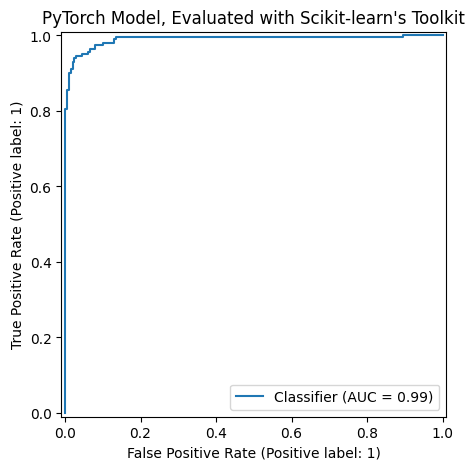

In [ ]:
import torch
import torch.nn as nn
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt

# === STAGE 1: Scikit-learn for data generation, splitting, and preprocessing ===
X, y = make_classification(n_samples=2000, n_features=15, n_informative=10, random_state=90)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=90, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# === STAGE 2: PyTorch for the model itself ===
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.int64)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

model = nn.Sequential(nn.Linear(15, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 2))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

model.train()
for epoch in range(100):
    optimizer.zero_grad()
    logits = model(X_train_t)
    loss = criterion(logits, y_train_t)
    loss.backward()
    optimizer.step()

# === STAGE 3: Scikit-learn for evaluation (the FULL toolkit mastered in the prior course) ===
model.eval()
with torch.inference_mode():
    test_logits = model(X_test_t)
    test_probs = torch.softmax(test_logits, dim=1)[:, 1].numpy()
    test_preds = test_logits.argmax(dim=1).numpy()

print(classification_report(y_test, test_preds))
print(f"ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")

from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, test_probs, ax=ax)
ax.set_title("PyTorch Model, Evaluated with Scikit-learn's Toolkit")
plt.show()


### Why This Combined Workflow Is Genuinely Standard Practice
Scikit-learn's preprocessing tools (`StandardScaler`, `OneHotEncoder`) and evaluation tools (`classification_report`, `RocCurveDisplay`, threshold optimization, Scikit-learn course Chapter 30) are mature, well-tested, and don't need to be reimplemented in PyTorch — using them **around** a PyTorch model (for everything except the model's own forward/backward computation) is not a compromise or a sign of incomplete PyTorch knowledge; it's the genuinely efficient, professional choice, directly the Scikit-learn course's Chapter 92 (here, Chapter 87) even-handed framing in action.

### Common Mistakes
- Reimplementing evaluation metrics manually in PyTorch when Scikit-learn's well-tested implementations are directly available and applicable to any NumPy-convertible prediction array — unnecessary duplicated effort with added bug risk.
- Forgetting the `.detach().cpu().numpy()` conversion (or equivalent) when passing PyTorch tensors into Scikit-learn functions, which expect NumPy arrays, not tensors.
- Using PyTorch for a task Scikit-learn would handle more simply and equally effectively — Chapter 87's framework should inform this choice at the project's outset, not be an afterthought.

### Quiz (Chapter 90)
1. Which three stages did this chapter's pipeline hand to Scikit-learn, and which one stage went to PyTorch?
2. Why is this combined workflow considered standard, efficient practice rather than a compromise?
3. What conversion step is required before passing PyTorch tensor output into any Scikit-learn evaluation function?


---
# CHAPTER 91 — MODEL SELECTION

## 1. Concept
A genuine decision framework spanning the full range from classical ML through LLMs — directly extending Chapter 87's PyTorch-vs-Scikit-learn framework and the Scikit-learn course's own Chapter 95 masterclass into the complete model landscape.

## 2. The Full Decision Framework


In [ ]:
def recommend_model_family(data_modality, dataset_size, interpretability_required,
                              latency_constraint_ms, compute_budget):
    """A genuinely reasoned decision function, directly codifying this chapter's framework."""
    recommendations = []

    if interpretability_required and data_modality == "tabular":
        recommendations.append("Logistic Regression or a single shallow Decision Tree (full interpretability)")
        return recommendations   # interpretability is often a HARD constraint, overriding other factors

    if data_modality == "tabular":
        if dataset_size < 10_000:
            recommendations.append("Classical ML (Random Forest/Gradient Boosting) -- insufficient data for DL's advantage")
        else:
            recommendations.append("Classical ML remains a strong default; consider a small MLP (Chapter 22) if")
            recommendations.append("genuine non-tabular signal (e.g., embeddings from another modality) needs fusing in")

    elif data_modality == "image":
        if dataset_size < 1000:
            recommendations.append("Transfer learning (Chapter 38) is ESSENTIAL -- too little data to train a CNN from scratch")
        else:
            recommendations.append("CNN (transfer learning still usually beneficial, Chapter 38-39)")

    elif data_modality == "text":
        if dataset_size < 5000:
            recommendations.append("Fine-tune a pretrained Transformer (Chapter 53, 57) -- small text datasets rarely")
            recommendations.append("support training an effective Transformer from scratch (Chapter 51)")
        else:
            recommendations.append("Fine-tune a pretrained Transformer, or train a smaller custom architecture")
            recommendations.append("(Chapter 83's bidirectional LSTM) if latency/compute is tightly constrained")

    if latency_constraint_ms is not None and latency_constraint_ms < 50:
        recommendations.append(f"NOTE: {latency_constraint_ms}ms constraint likely requires quantization (Ch 59)")
        recommendations.append("and/or a genuinely smaller architecture -- large models may not meet this budget")

    if compute_budget == "limited":
        recommendations.append("NOTE: prefer transfer learning/fine-tuning (LoRA, Ch 58) over training from scratch")

    return recommendations


scenario = recommend_model_family(
    data_modality="text", dataset_size=2000, interpretability_required=False,
    latency_constraint_ms=100, compute_budget="limited",
)
print("Scenario: small text dataset, limited compute, moderate latency need")
for r in scenario:
    print(" -", r)


Scenario: small text dataset, limited compute, moderate latency need
 - Fine-tune a pretrained Transformer (Chapter 53, 57) -- small text datasets rarely
 - support training an effective Transformer from scratch (Chapter 51)
 - NOTE: prefer transfer learning/fine-tuning (LoRA, Ch 58) over training from scratch


### Interview Insight
**Q: A startup has 3,000 labeled customer support tickets and wants a classifier, with a limited compute budget and no dedicated ML infrastructure team. Walk through your model selection reasoning.**
A: 3,000 samples is a genuinely small dataset for training any Transformer architecture from scratch (Chapter 51) — that approach would very likely overfit badly given the combination of limited data and typical Transformer parameter counts. The limited compute budget and lack of dedicated infrastructure point toward fine-tuning a small, pretrained Transformer (Chapter 53, ideally with LoRA, Chapter 58, to keep both compute and engineering complexity minimal) rather than training anything from scratch — leveraging the pretrained model's existing general language understanding and only adapting a small fraction of parameters to this specific classification task. I'd also establish a classical ML baseline (TF-IDF + Logistic Regression, directly the Scikit-learn course's Chapter 63 pattern) first, specifically because it's extremely cheap to build and might already be entirely sufficient for this task's actual accuracy requirements — only justifying the added complexity of a fine-tuned Transformer if it demonstrably, meaningfully outperforms that cheap baseline on the startup's actual held-out evaluation data.

### Quiz (Chapter 91)
1. Why does the decision function treat `interpretability_required` as potentially overriding other factors?
2. Why does dataset size change the recommendation differently for tabular versus text/image data?
3. Why does this framework recommend establishing a classical ML baseline even when ultimately planning to use a Transformer?


---
# CHAPTER 92 — AI SYSTEM DESIGN

## Concept
A set of realistic system-design scenarios, each requiring you to reason through the full pipeline: Data → Preprocessing → Model → Training → Evaluation → Deployment → Monitoring — directly the format Chapter 97's interview mastery chapter will revisit in condensed form.

## Problem 1: Design a Real-Time Image Classification System
**Scenario**: A retail app needs to identify products from a user's photo, with sub-200ms latency, on a mix of iOS/Android devices.

<details><summary>Reasoning</summary>

- **Data**: product images, likely needing significant augmentation (Chapter 37) given varied user-captured lighting/angles.
- **Model**: a mobile-optimized architecture (MobileNet-family, Chapter 39/67), via transfer learning (Chapter 38) from an ImageNet-pretrained backbone.
- **Optimization**: int8 quantization (Chapter 59) essential for the latency target on mobile CPUs; TorchScript/mobile export (Chapter 61, 68).
- **Deployment**: on-device inference (Chapter 68) to meet the latency target without a network round-trip; cloud fallback for cases on-device confidence is low.
- **Monitoring**: prediction distribution drift (Chapter 65) as the product catalog evolves; device-diversity-aware performance testing (Chapter 68).
</details>

## Problem 2: Design a Fraud Detection Neural Network
**Scenario**: A payments company needs real-time fraud scoring, extreme class imbalance (~0.1% fraud), sub-50ms latency.

<details><summary>Reasoning</summary>

- **Data**: tabular transaction features — this is a strong signal toward classical ML (Chapter 87's framework) rather than deep learning by default, given tabular data and a latency-critical, low-capacity-need scenario; a well-tuned Gradient Boosting model (Scikit-learn course) is a genuinely strong default here.
- **If deep learning is genuinely justified** (e.g., incorporating embeddings for high-cardinality categorical features, or sequential transaction history via an LSTM, Chapter 85-style): extreme care needed with class weighting (`BCEWithLogitsLoss`'s `pos_weight`), and the 50ms constraint likely demands a small, quantized model.
- **Evaluation**: PR-AUC, not ROC-AUC, given the severe imbalance (Scikit-learn course Chapter 29, 74); threshold optimized against real fraud/false-alarm cost asymmetry (Chapter 82's project directly demonstrated this pattern).
- **Deployment**: real-time API (Chapter 63) with aggressive latency monitoring (p99, Chapter 65).
</details>

## Problem 3: Design a Recommendation System
**Scenario**: An e-commerce platform wants personalized recommendations, millions of users/items, needs to update frequently as the catalog changes.

<details><summary>Reasoning</summary>

- Directly Chapter 85's neural collaborative filtering approach, scaled: embedding tables for millions of users/items (genuinely large embedding matrices, Chapter 48, requiring careful memory consideration).
- **Negative sampling** (Chapter 85) essential, given purely-positive interaction data.
- **Serving**: precomputed item embeddings, updated on a batch cadence; approximate nearest-neighbor search (a specialized technique beyond this course's scope) for efficiently finding top-K recommendations among millions of items at serving time.
- **Evaluation**: offline ranking metrics as a first check, but genuine validation requires A/B testing (Chapter 66) against real business metrics (click-through, conversion) before full rollout.
</details>

## Problem 4: Design an LLM Inference Service
**Scenario**: A company wants to serve a fine-tuned LLM to internal employees, with cost control being a primary concern.

<details><summary>Reasoning</summary>

- **Fine-tuning**: LoRA (Chapter 58) over full fine-tuning (Chapter 57), given cost sensitivity.
- **Serving optimization**: quantization (Chapter 59, likely int8 or more aggressive), request batching (Chapter 62) to maximize throughput per GPU-hour.
- **Cost control**: careful monitoring of actual usage patterns (Chapter 65) to right-size serving infrastructure; consider a smaller base model if the specific internal use case doesn't genuinely require a larger model's full capability (Chapter 91's model-selection discipline).
- **Deployment**: REST API (Chapter 63) with authentication/access control for internal-only use; health checks and monitoring (Chapter 65) given LLM serving's relatively higher per-request cost compared to smaller models.
</details>

### Quiz (Chapter 92)
Pick one of the four problems above and write out your own full reasoning before revealing the suggested approach — then compare where you agreed and diverged.


---

## END OF NOTEBOOK 15 — What You Should Now Be Able To Do
- Independently execute a complete time-series forecasting project, including a mandatory classical-ML baseline and an honest assessment of when deep learning is genuinely justified.
- Apply the full PyTorch-vs-Scikit-learn decision framework, and recognize that combining both in one project is standard, efficient professional practice, not a compromise.
- Fluently convert between Pandas, NumPy, and PyTorch tensors in both directions, handling every common dtype/mixed-type pitfall.
- Visualize PyTorch-specific diagnostics (learned embeddings, attention weights) using Matplotlib/Seaborn, directly verifying abstract architectural claims empirically.
- Apply a complete, nuanced model-selection framework spanning classical ML through LLMs, reasoning from data modality, size, interpretability, latency, and compute constraints.
- Reason through realistic AI system design scenarios end-to-end, from data through deployment and monitoring.

## Before Moving to Notebook 16 (Chapters 93–98: Interview Mastery, Coding Interview, Debugging Interview, Real-World AI Scenarios, Common PyTorch Interview Traps, Performance Engineering)
 